# REPD — Appeals timeline (projects refused since 1 Jan 2024)

Follows every project **refused planning permission between 1 Jan 2024 and 31 Dec 2025** and what happened next: whether it appealed, how the appeal ended, and whether it moved on to construction.
Each column is a quarter-end snapshot of the stage each project was at on that date. Newly refused projects fan in from the top.

**How stage is worked out:** stages come from each project's own dates (refused → appeal lodged → appeal granted / refused / withdrawn → under construction → operational), not from its current status. Two cases have no date of their own:
- *Revised / resubmitted* (current status Revised) is placed at the record's last-updated date.
- *Granted, no appeal recorded* covers projects granted later with no appeal record in REPD (re-determined, resubmitted, or an appeal REPD didn't record).

**Data caveats:** about half the appeal wins have no *Appeal lodged* date, so in the chart they jump straight from Refused to Appeal granted. Appeal losses are likely recorded late, so recent quarters overstate the win rate.

In [1]:
from pathlib import Path

import pandas as pd

from repd.processor import REPDProcessor
from repd.visualise import plot_alluvial

REPD_CSV = Path("../data/REPD_Publication_Q4_2025.csv")
START = pd.Timestamp("2024-01-01")

## 1. Load and build the cohort

In [2]:
processor = REPDProcessor(REPD_CSV, encoding="latin-1")
df = processor.convert_datetime(processor.load())
# End at the last full quarter before the latest REPD update, matching notebook 03.
end = df["Record Last Updated (dd/mm/yyyy)"].max().to_period("Q").start_time - pd.Timedelta(days=1)

refused = df["Planning Permission Refused"]
cohort = df[refused.between(START, end)].copy()
status = cohort["Development Status (short)"]
appealed = cohort[["Appeal Lodged", "Appeal Granted", "Appeal Refused", "Appeal Withdrawn"]].notna().any(axis=1)

print(f"Cohort: {len(cohort):,} projects refused {START:%d %b %Y} → {end:%d %b %Y}")
print(f"Appealed: {appealed.sum():,} ({appealed.mean():.0%})")
pd.crosstab(status, appealed.rename("appealed"))

Cohort: 357 projects refused 01 Jan 2024 → 31 Dec 2025
Appealed: 71 (20%)


appealed,False,True
Development Status (short),,
Appeal Withdrawn,0,1
Application Refused,234,1
Application Submitted,1,0
Awaiting Construction,11,69
Revised,40,0


## 2. Stage of every project at each quarter-end

In [3]:
# Stage → date it was reached, in pipeline order (ties on the same date resolve to the later stage).
outcome = cohort[["Appeal Granted", "Appeal Refused", "Appeal Withdrawn"]].min(axis=1)
no_appeal_grant = cohort["Planning Permission Granted"].where(
    ~appealed & (cohort["Planning Permission Granted"] > cohort["Planning Permission Refused"])
)
STAGES = {
    "Refused, no appeal (yet)":     cohort["Planning Permission Refused"],
    "Revised / resubmitted":        cohort["Record Last Updated (dd/mm/yyyy)"].where(status == "Revised"),
    "Appeal lodged":                cohort["Appeal Lodged"].fillna(outcome),  # missing lodge date → same day as outcome
    "Appeal withdrawn":             cohort["Appeal Withdrawn"],
    "Appeal refused":               cohort["Appeal Refused"],
    "Appeal granted":               cohort["Appeal Granted"],
    "Granted, no appeal recorded":  no_appeal_grant,
    "Under construction":           cohort["Under Construction"],
    "Operational":                  cohort["Operational"],
}
rank = {s: i for i, s in enumerate(STAGES)}

steps = pd.concat(
    [d.dropna().rename("date").to_frame().assign(stage=s) for s, d in STAGES.items()]
).sort_values("date", kind="stable")
# Nothing can happen before the refusal (catches data-entry errors).
steps["date"] = steps["date"].clip(lower=cohort["Planning Permission Refused"].reindex(steps.index))
steps["rank"] = steps["stage"].map(rank)
steps = steps.sort_values(["date", "rank"])

snapshots = list(pd.date_range(START, end, freq="QE"))


def stage_on(d: pd.Timestamp) -> pd.Series:
    """Latest stage each project had reached by date d (NaN if not yet refused)."""
    return steps[steps["date"] <= d].groupby(level=0)["stage"].last().reindex(cohort.index)


states = pd.DataFrame({d: stage_on(d) for d in snapshots})

# Self-checks: every project is placed by the last snapshot, the cohort only grows,
# and every appealed project ends in an appeal stage or beyond.
assert states[end].notna().all()
assert states.notna().sum().is_monotonic_increasing
assert (states.loc[appealed, end].map(rank) >= rank["Appeal lodged"]).all()

states.apply(pd.Series.value_counts).fillna(0).astype(int).reindex(list(STAGES)).dropna(how="all").rename(
    columns=lambda d: f"{d:%b %Y}"
)

,Mar 2024,Jun 2024,Sep 2024,Dec 2024,Mar 2025,Jun 2025,Sep 2025,Dec 2025
"Refused, no appeal (yet)",35.0,66.0,103.0,125.0,145.0,189.0,203.0,238.0
Revised / resubmitted,2.0,8.0,12.0,23.0,31.0,34.0,37.0,40.0
Appeal lodged,0.0,4.0,10.0,17.0,15.0,12.0,5.0,2.0
Appeal withdrawn,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
Appeal refused,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
Appeal granted,2.0,2.0,2.0,9.0,25.0,36.0,57.0,67.0
"Granted, no appeal recorded",0.0,0.0,0.0,0.0,0.0,3.0,8.0,8.0


## 3. Timeline

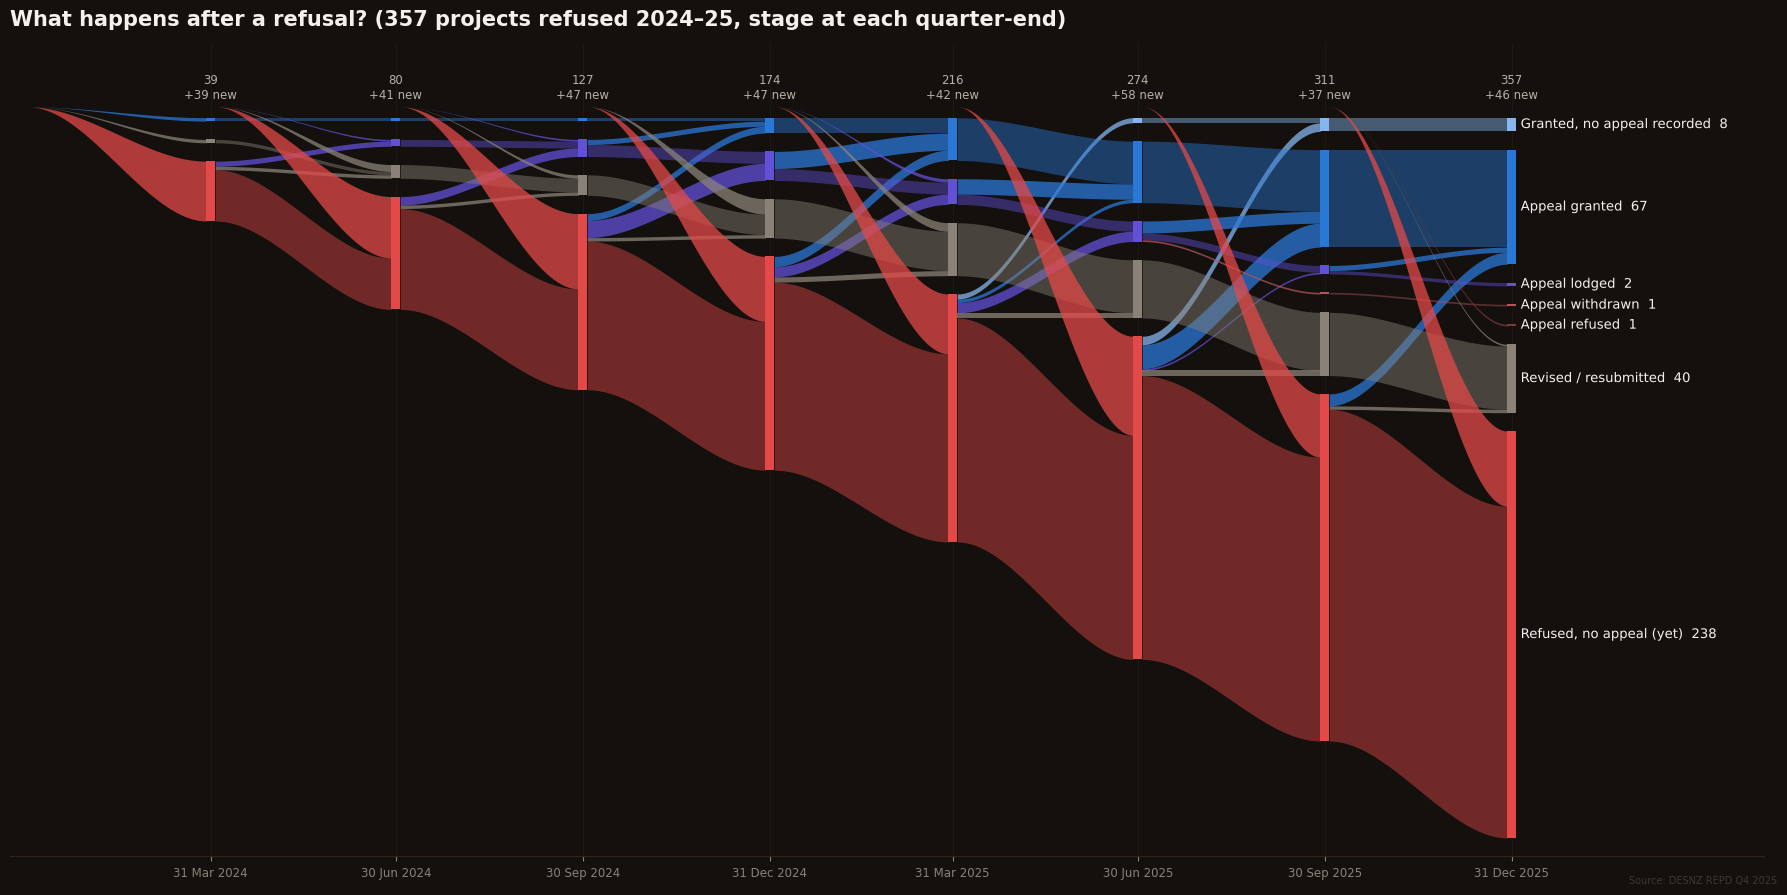

In [4]:
ORDER = ["Operational", "Under construction", "Granted, no appeal recorded", "Appeal granted",
         "Appeal lodged", "Appeal withdrawn", "Appeal refused",
         "Revised / resubmitted", "Refused, no appeal (yet)"]
COLORS = {
    "Refused, no appeal (yet)":    "#e34948",
    "Revised / resubmitted":       "#8a8278",
    "Appeal lodged":               "#6250d6",
    "Appeal withdrawn":            "#b5545c",
    "Appeal refused":              "#7a3b3b",
    "Appeal granted":              "#2a78d6",
    "Granted, no appeal recorded": "#86b6ef",
    "Under construction":          "#eda100",
    "Operational":                 "#1baf7a",
}

fig = plot_alluvial(
    states,
    order=ORDER,
    colors=COLORS,
    title=f"What happens after a refusal? ({len(cohort):,} projects refused 2024–25, stage at each quarter-end)",
    origin=START,
    credit="Source: DESNZ REPD Q4 2025",
)
fig.savefig("appeals_timeline.png", dpi=150, bbox_inches="tight")

## 4. Appeal timings (months)

In [5]:
def months(a: pd.Series, b: pd.Series) -> pd.Series:
    m = ((b - a).dt.days / 30.44).dropna()
    m = m[m >= 0]
    return pd.Series({"n": len(m), "mean": m.mean(), "sd": m.std(), "median": m.median()})


c = cohort
pd.DataFrame({
    "Refused → appeal lodged":   months(c["Planning Permission Refused"], c["Appeal Lodged"]),
    "Appeal lodged → decided":   months(c["Appeal Lodged"], outcome),
    "Refused → appeal decided":  months(c["Planning Permission Refused"], outcome),
}).T.astype({"n": int}).round(1)

,n,mean,sd,median
Refused → appeal lodged,35,4.4,2.1,4.7
Appeal lodged → decided,35,5.1,2.5,4.4
Refused → appeal decided,69,8.8,3.3,9.2
